# Incident radiative heat-flux imaging from real steel-wall thermography


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `fire_wall_inverse_heatflux` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：temperature (1, 25, 66, 50) float64：Absolute steel-panel temperatures in Kelvin, ordered time, vertical, horizontal, including a one-pixel spatial collar.；time (1, 25) float64：Observation times from 100 to 124 seconds after ignition.；x (1, 50) float64：Horizontal observation coordinates in metres, increasing with column index.；y (1, 66) float64：Vertical observation coordinates in metres, increasing with row index.。恢复目标：空间时间incident radiative heatflux，kW/m²。

获取模型：薄壁能量储存、对流、辐射及侧向导热平衡给吸收辐射通量。实际恢复算法：solvers.reconstruct显式时间导数/Laplacian/温度相关材料参数，并代数求q。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:62原始HFITS参考；:64历史作者估计不同模型，也不是真flux。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：fire_wall_inverse_heatflux.ipynb单元0：5. Results；fire_wall_inverse_heatflux.ipynb单元2有保存图；图内容由该单元调用的本地visualization函数生成；fire_wall_inverse_heatflux.ipynb单元3：Scientific comparisons and limits。图/比较代码位于单元1, 2, 4（从0计数）。代码单元3个，带execution_count的3个，保存PNG输出3幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


A heated steel panel stores heat, emits radiation from both faces, exchanges heat with gas, and conducts heat laterally. The measured temperature field therefore does not directly equal the local incident exposure. We reconstruct a spatial heat-flux field at every pixel and time in a bound 25-frame window, using an explicit thin-plate inverse energy balance.

The observations are an existing processed real thermography field in the CC BY 4.0 FSRI dataset v1.0.0 (DiDomizio,2024; DOI10.5281/zenodo.10543089), heptane-fire HEPT_FLUXFIELD. We select times100…124s, a66-by50 measured window, and its64-by48 interior target. No new synthetic observations are generated. The measured one-pixel collar supplies all target-pixel spatial neighbors.

**Provenance is separated:** historical author irradiance estimates in that dataset have their own fitted convection/processing; our exact-data original HFITS run uses the selected nominal material and constant-convection options; the fresh local result below is recomputed from temperature using src only. Neither method output is actual measured flux truth. The source data README calls temperature degrees Celsius, but the actual stored absolute values begin near293K at ignition and agree with the independently recorded20.77°C room condition after conversion. We preserve those Kelvin values and explicitly select the original HFITS Kelvin input branch; no273.15 is added. This discrepancy and its checks are recorded in test/validation.md.

## 2. Data

`data/raw_data.npz` contains existing processed real thermography observations and their acquisition coordinates. All arrays use an explicit batch axis.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| temperature | (1, 25, 66, 50) | float64 | Absolute steel-panel temperatures in Kelvin, ordered time, vertical, horizontal, including a one-pixel spatial collar. |
| time | (1, 25) | float64 | Observation times from 100 to 124 seconds after ignition. |
| x | (1, 50) | float64 | Horizontal observation coordinates in metres, increasing with column index. |
| y | (1, 66) | float64 | Vertical observation coordinates in metres, increasing with row index. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Panel material | 304 stainless steel | 1 | Thin panel observed by infrared thermography. |
| Thickness d | 0.000793 | m | Selected panel thickness. |
| Emissivity and absorptivity epsilon | 0.94 | 1 | Equal grey-surface values on both faces. |
| Density rho | 8050 | kg/m³ | Selected nominal steel material law. |
| Conductivity k(T) | 8.1119 ln(T / 1 K) - 30.377 | W/(m K) | Nominal temperature-dependent material law; T is Kelvin. |
| Heat capacity cp(T) | 1000 [0.1414 ln(T / 1 K) - 0.3534] | J/(kg K) | Nominal temperature-dependent material law. |
| Ambient T(a) | 293.15 | K | Fixed room-temperature boundary assumption. |
| Exposed-face h(f) | 10 | W/(m² K) | Fixed constant-convection model assumption. |
| Back-face h(b) | 10 | W/(m² K) | Fixed constant-convection model assumption. |
| Stefan–Boltzmann constant sigma | 5.67 times 10^-8 | W/(m² K^4) | Rounded value used by the selected energy model. |
| Spatial sampling | 0.0127 in both directions | m | Half-inch square observation grid. |
| Temporal sampling | 1 | s | Uniform spacing of the supplied frames. |
| Target boundary information | Measured one-pixel spatial collar | 1 | Supplies all four neighbors of each target pixel. |
| Through-thickness approximation | Uniform temperature | 1 | Thin-skin energy balance; no thickness-resolved unknown. |
| Spatial coordinates | Increasing x and y; arrays ordered time,y,x | 1 | Coordinate arrays fix positions without image-axis ambiguity. |

The temperatures are already on an absolute Kelvin scale. Preserve their stored numerical precision; do not add 273.15. The chosen material and convection laws define the reference physical approximation and are not independently measured heat-flux truth. No other file is required to formulate the inverse problem.

## 3. Physics

### Forward physics and closed-form inverse

For Kelvin temperature $T$, density $\rho$, specific heat $c_p(T)$, thickness $d$, emissivity/absorptivity $\epsilon$, and ambient $T_a$, define storage $S=\rho c_p(T)d\,\partial T/\partial t$, convection $C=(h_f+h_b)(T-T_a)$, radiative loss $R=\epsilon\sigma(2T^4-T_a^4)$, and lateral conduction $K=k(T)d\nabla^2T$, all in W/m². Then incident irradiance is


$$
q=\frac{S+C+R-K}{1000\epsilon}\quad[\mathrm{kW/m^2}].
$$


Both faces emit; ambient infrared radiation enters on the back face; the exposed-face incoming radiation is unknown. At ambient equilibrium, incident flux is $\sigma T_a^4$, not zero. The local-conductivity model uses $k(T)\nabla^2T$, not a silently substituted full divergence of variable conductivity.

The selected original option uses nominal steel properties $k=8.1119\ln(T/1K)-30.377$, $c_p=1000[0.1414\ln(T/1K)-0.3534]$, $\rho=8050$, $d=0.000793$m, $\epsilon=0.94$, $T_a=293.15$K, $h_f=h_b=10$W/(m²K), and $\sigma=5.67\times10^{-8}$. These are model assumptions, not independently measured ground truth. We preserve the source's second-order central/time-endpoint differences and square-grid five-point Laplacian. The inverse is a direct formula; iterative convergence or training curves would be artificial.

## 4. Method

Evaluate the energy balance directly at all 25 measured times and the 64 by 48 interior pixels. Second-order centered temporal differences (second-order endpoint rules at the time limits) and the measured one-pixel collar provide $\partial_tT$ and the square-grid five-point $\nabla^2T$. Compute temperature-dependent $c_p,k$, then $q=(S+C+R-K)/(1000\epsilon)$. The factor 1000 converts W/m^2 to kW/m^2; division by absorptivity converts absorbed to incident irradiance. No iteration or learned model is involved. Omitting storage/conduction or varying convection are measured-data sensitivity analyses, not alternate labels for the standard inverse.

## 5. Results




In [1]:
from pathlib import Path
import sys,os,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
if not (root/'data/raw_data.npz').exists():raise RuntimeError('Execute from task or notebooks directory')
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.physics_model import predicted_storage
from src.visualization import make_figures,similarity,export_figures
data=load_data(root/'data/raw_data.npz')
t0=time.perf_counter();q,terms=reconstruct(data);runtime=time.perf_counter()-t0
with np.load(root/'notebooks/reference_outputs/upstream_hfits.npz',allow_pickle=False) as a:upstream=a['reconstruction'][0].copy()
with np.load(root/'notebooks/reference_outputs/historical_author_estimate.npz',allow_pickle=False) as a:historical=a['incident_flux'].copy()
print('Fresh complete-window inverse runtime [s]:',runtime)
print('Fresh flux range [kW/m²]:',q.min(),q.max())
print('NCC, dynamic-range NRMSE vs unmodified original HFITS:',similarity(q,upstream))
print('Maximum absolute original parity discrepancy [kW/m²]:',np.max(abs(q-upstream)))

Fresh complete-window inverse runtime [s]: 0.0030262000000220723
Fresh flux range [kW/m²]: 5.106361275916989 27.854195715630976
NCC, dynamic-range NRMSE vs unmodified original HFITS: (1.0, 8.14362535444289e-18)
Maximum absolute original parity discrepancy [kW/m²]: 7.105427357601002e-15


Fresh term omission RMS changes [kW/m²]:
No conduction: 0.0529185828929288
No storage: 6.263976510302886
Forward energy balance max residual [W/m²]: 7.275957614183426e-12
Historical field finite fraction: 1.0
Historical comparison RMS [kW/m²], different processing/model: 3.2389724136789133


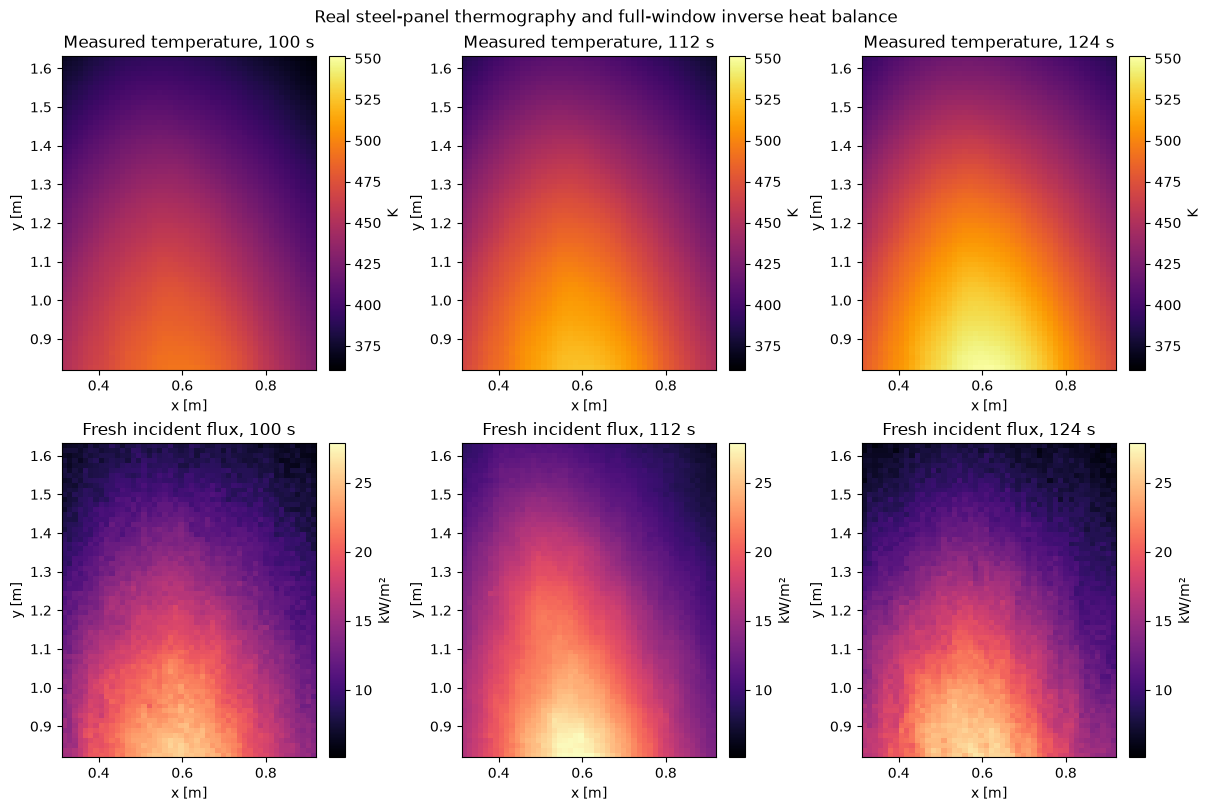

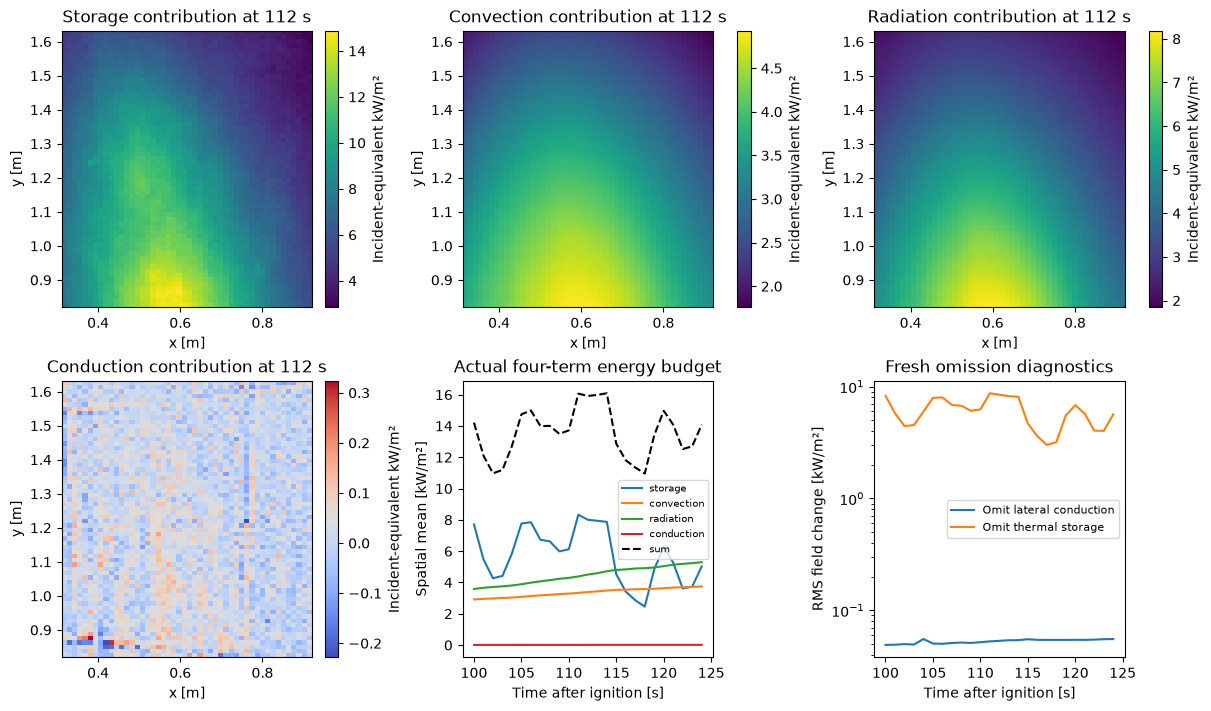

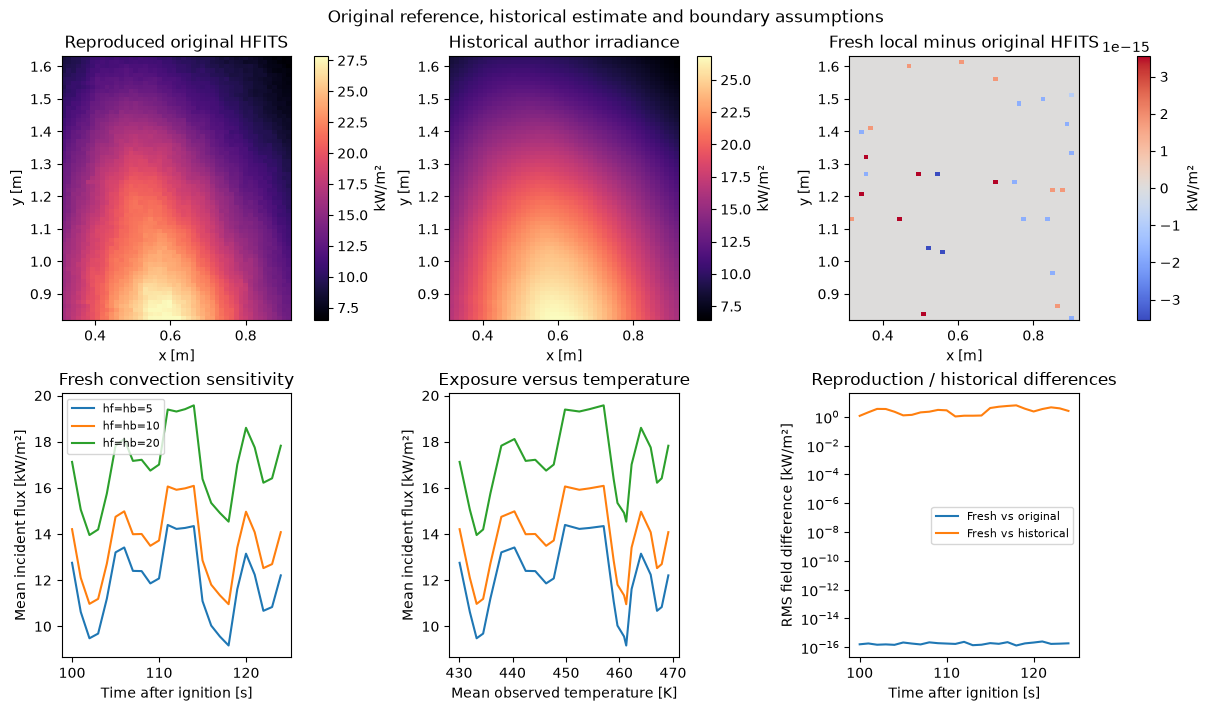

In [2]:
sensitivity={}
for h in [5.,10.,20.]:
    sensitivity[h]=reconstruct(data,h_exposed=h,h_unexposed=h)[0]
no_conduction=q+terms['conduction']/940
no_storage=q-terms['storage']/940
print('Fresh term omission RMS changes [kW/m²]:')
print('No conduction:',np.sqrt(np.mean((q-no_conduction)**2)))
print('No storage:',np.sqrt(np.mean((q-no_storage)**2)))
print('Forward energy balance max residual [W/m²]:',np.max(abs(predicted_storage(data['temperature'],q)-terms['storage'])))
print('Historical field finite fraction:',np.isfinite(historical).mean())
print('Historical comparison RMS [kW/m²], different processing/model:',np.sqrt(np.nanmean((q-historical)**2)))
figures=make_figures(data,q,terms,upstream,historical,sensitivity)
plt.show()

### Scientific comparisons and limits

Group1 shows three measured-temperature snapshots paired with the freshly reconstructed incident-flux snapshots on common physical coordinates. Temperature increases are spatially smooth, while derivative-based flux reveals time-dependent local exposure.

Group2 resolves all four actual energy contributions and computes fresh omission diagnostics. The no-conduction calorimeter approximation and no-storage approximation use the same measured data; neither is passed off as the selected standard reconstruction. This preserves the scientifically relevant spatial versus pointwise calorimeter distinction without inventing an iterative solver.

Group3 separates numerical reproduction from model agreement. It overlays the independently rerun original HFITS field and the historical author's dataset estimate, displays their very different levels of discrepancy, and actively recomputes convection-model sensitivities. Historical author estimates are neither fresh nor truth, and differences reflect distinct convection estimation and processing. If an archived historical field contains missing values, only its diagnostic RMS uses finite entries; the standard output and Judge have no mask.

The thin-skin approximation neglects through-thickness structure; nominal convection and local-conductivity laws limit quantitative accuracy. The original dataset contains processed thermal observations; we do not claim sensor-raw calibration, independent true incident flux, or exact reproduction of every full-experiment fire analysis. The selected complete benchmark window is reconstructed actively.


In [3]:
spec=importlib.util.spec_from_file_location('standalone_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=q[None])
report,status=judge.evaluate(root/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert status==0
sources={**data,'fresh_incident_flux':q,'original_hfits_incident_flux':upstream,'historical_author_estimate':historical,'fresh_no_conduction':no_conduction,'fresh_no_storage':no_storage,**{f'energy_{k}_W_m2':v for k,v in terms.items()}}
for h,field in sensitivity.items():sources[f'fresh_h_{h:g}_flux']=field
export=Path(os.environ['IMAGING_PRIVATE_EXPORT'])
export_figures(figures,sources,export)
print('Private PNG/SVG/PDF and exact numeric sources exported:',export)

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0,
    "nrmse": 8.14362535444289e-18,
    "balance_nrmse": 2.012687964880763e-15
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "balance_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    }
  },
  "errors": []
}


Private PNG/SVG/PDF and exact numeric sources exported: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch4_20261021\astro_earth_mechanics\hfits_figures


## 6. Conclusion


The fresh local closed-form inverse reproduces an independently executed unmodified HFITS reference across all25times and3072 spatial target pixels. Analytic temporal/spatial/equilibrium checks and an independent standalone energy-balance evaluator support mathematical consistency. The component, omission, historical and convection-sensitivity comparisons show why numerical reproducibility should be distinguished from physical-model certainty.
